# India Flood Prediction Dataset — Data Description, Preprocessing & EDA

**Purpose:** document the supplied dataset, clean and validate it, perform univariate, bivariate and multivariate exploratory analysis, and record report-ready observations.

> **Important data-provenance note:** This notebook analyses the CSV supplied with the project (`final_india_flood_prediction_dataset.csv`). The CSV itself does not contain a source URL, data dictionary, collection notes, or citations. Therefore, its complete provenance cannot be verified from the file alone. The official links in the source section below are *authoritative places to obtain/verify relevant raw input layers* (rainfall, flood observations, land cover, population and elevation); they are **not proof** that this exact CSV was downloaded from those portals. Do not claim that the entire CSV came from one official website unless you can trace the original preparation script or download records.

## 1. Imports and loading the dataset

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# If the CSV is in the same folder as this notebook, this path works.
# Otherwise replace it with the full path to final_india_flood_prediction_dataset.csv.
DATA_PATH = "final_india_flood_prediction_dataset.csv"

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print("Dataset loaded successfully")
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
display(df.head())

Dataset loaded successfully
Rows: 7086 | Columns: 29


,sample_id,state,district,sub_district,latitude,longitude,flood_occurred,geographical_area_ha,elevation_m,slope_deg,...,max_rainfall_24h_mm_2014,max_rainfall_3d_mm_2014,max_rainfall_7d_mm_2014,extreme_rain_days_p90_2014,annual_rainfall_mm_2015,max_rainfall_24h_mm_2015,max_rainfall_3d_mm_2015,max_rainfall_7d_mm_2015,extreme_rain_days_p90_2015,sample_type
0,1,Rajasthan,UDAIPUR,JHAROL,25.417371,70.614263,1,137083.44,1068.071337,8.596125,...,19.017157,19.358326,19.503959,365,471.310900,147.874100,175.926136,218.152189,365,observed_flood
1,2,Uttar Pradesh,BAHRAICH,SIKANDARPUR,27.250000,74.750000,0,35166.41,1153.594982,5.609654,...,82.297890,106.783504,153.122218,37,579.037048,44.906273,68.791124,97.103766,37,pseudo_negative_matched_pool
2,3,Tamil Nadu,PERAMBALUR,PERAMBALUR,24.704928,81.781902,1,33085.04,979.654510,2.683912,...,159.598340,197.716774,267.844933,37,760.164100,58.311855,109.169992,136.058322,37,observed_flood
3,4,Jharkhand,GIRIDIH,GANDE,28.500000,81.000000,0,35682.61,1180.829039,4.537916,...,146.624863,233.014654,289.461754,37,988.383606,77.998863,119.240997,212.432541,37,pseudo_negative_matched_pool
4,5,Andhra Pradesh,KRISHNA,VATSAVAI,27.750000,93.750000,0,17994.77,1040.433542,7.536974,...,143.869431,300.685020,443.446559,37,2956.618896,156.276505,300.818333,423.713407,37,pseudo_negative_matched_pool


## 2. Dataset description and data acquisition

### Dataset overview (as observed in the supplied CSV)

- **Dataset file:** `final_india_flood_prediction_dataset.csv`
- **Rows and columns:** 7,086 records and 29 columns.
- **Geographic coverage:** 30 distinct state/UT labels; district and sub-district names are also present.
- **Target:** `flood_occurred` (binary: 1 = flood, 0 = non-flood).
- **Sample composition:** the file labels 3,543 records as `observed_flood` and 3,543 as `pseudo_negative_matched_pool`.
- **Rainfall years represented in column names:** 2014 and 2015.
- **Data types:** numeric identifiers, coordinates and measurements; categorical administrative/geographic attributes; binary target and sample-type label.

### Feature dictionary

The descriptions below are interpretations of the column names and units embedded in them. Confirm them against the original data-generation documentation before treating them as authoritative definitions.

In [2]:
feature_dictionary = pd.DataFrame([
    ("sample_id", "Record identifier", "Integer"),
    ("state", "State/UT label", "Categorical"),
    ("district", "District label", "Categorical"),
    ("sub_district", "Sub-district label", "Categorical"),
    ("latitude", "Record latitude", "Numeric (degrees)"),
    ("longitude", "Record longitude", "Numeric (degrees)"),
    ("flood_occurred", "Binary flood outcome/label (1 or 0)", "Binary"),
    ("geographical_area_ha", "Geographical area", "Numeric (hectares)"),
    ("elevation_m", "Elevation", "Numeric (metres)"),
    ("slope_deg", "Terrain slope", "Numeric (degrees)"),
    ("soil_type", "Soil category", "Categorical"),
    ("land_cover", "Land-cover category", "Categorical"),
    ("river_distance_km", "Distance to river", "Numeric (kilometres)"),
    ("drainage_density_km_per_km2", "Drainage density", "Numeric (km/km²)"),
    ("built_up_pct", "Built-up area percentage", "Numeric (percent)"),
    ("population_density_per_km2", "Population density", "Numeric (people/km²)"),
    ("rain_grid_latitude", "Latitude of rainfall grid cell", "Numeric (degrees; missing values present)"),
    ("rain_grid_longitude", "Longitude of rainfall grid cell", "Numeric (degrees; missing values present)"),
    ("annual_rainfall_mm_2014", "Annual rainfall for 2014", "Numeric (mm)"),
    ("max_rainfall_24h_mm_2014", "Maximum 24-hour rainfall for 2014", "Numeric (mm)"),
    ("max_rainfall_3d_mm_2014", "Maximum 3-day rainfall for 2014", "Numeric (mm)"),
    ("max_rainfall_7d_mm_2014", "Maximum 7-day rainfall for 2014", "Numeric (mm)"),
    ("extreme_rain_days_p90_2014", "Count of extreme-rain days using a P90 threshold in 2014", "Numeric (days; verify definition)"),
    ("annual_rainfall_mm_2015", "Annual rainfall for 2015", "Numeric (mm)"),
    ("max_rainfall_24h_mm_2015", "Maximum 24-hour rainfall for 2015", "Numeric (mm)"),
    ("max_rainfall_3d_mm_2015", "Maximum 3-day rainfall for 2015", "Numeric (mm)"),
    ("max_rainfall_7d_mm_2015", "Maximum 7-day rainfall for 2015", "Numeric (mm)"),
    ("extreme_rain_days_p90_2015", "Count of extreme-rain days using a P90 threshold in 2015", "Numeric (days; verify definition)"),
    ("sample_type", "Construction/source class of sample", "Categorical"),
], columns=["Feature", "Description (inferred)", "Data type / unit"])
display(feature_dictionary)

,Feature,Description (inferred),Data type / unit
0,sample_id,Record identifier,Integer
1,state,State/UT label,Categorical
2,district,District label,Categorical
3,sub_district,Sub-district label,Categorical
4,latitude,Record latitude,Numeric (degrees)
5,longitude,Record longitude,Numeric (degrees)
6,flood_occurred,Binary flood outcome/label (1 or 0),Binary
7,geographical_area_ha,Geographical area,Numeric (hectares)
8,elevation_m,Elevation,Numeric (metres)
9,slope_deg,Terrain slope,Numeric (degrees)


## 3. Initial inspection and structure

In [3]:
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
display(df.dtypes.rename("dtype").to_frame())
print("\nNumerical summary:")
display(df.describe().T)
print("\nCategorical summary:")
display(df.describe(include="object").T)

Shape: (7086, 29)

Column names:
['sample_id', 'state', 'district', 'sub_district', 'latitude', 'longitude', 'flood_occurred', 'geographical_area_ha', 'elevation_m', 'slope_deg', 'soil_type', 'land_cover', 'river_distance_km', 'drainage_density_km_per_km2', 'built_up_pct', 'population_density_per_km2', 'rain_grid_latitude', 'rain_grid_longitude', 'annual_rainfall_mm_2014', 'max_rainfall_24h_mm_2014', 'max_rainfall_3d_mm_2014', 'max_rainfall_7d_mm_2014', 'extreme_rain_days_p90_2014', 'annual_rainfall_mm_2015', 'max_rainfall_24h_mm_2015', 'max_rainfall_3d_mm_2015', 'max_rainfall_7d_mm_2015', 'extreme_rain_days_p90_2015', 'sample_type']

Data types:


,dtype
sample_id,int64
state,object
district,object
sub_district,object
latitude,float64
longitude,float64
flood_occurred,int64
geographical_area_ha,float64
elevation_m,float64
slope_deg,float64



Numerical summary:


,count,mean,std,min,25%,50%,75%,max
sample_id,7086.0,3543.500000,2045.696336,1.000000,1772.250000,3543.500000,5314.750000,7.086000e+03
latitude,7086.0,23.030650,7.249842,8.004988,17.572480,23.500000,28.010935,3.725000e+01
longitude,7086.0,80.846648,7.341287,68.000000,75.250000,79.250000,86.024152,9.725000e+01
flood_occurred,7086.0,0.500000,0.500035,0.000000,0.000000,0.500000,1.000000,1.000000e+00
geographical_area_ha,7086.0,64251.054643,63428.911530,3.000000,25758.202500,48398.075000,85635.800000,2.140069e+06
elevation_m,7086.0,962.452931,171.698985,353.013551,865.126832,990.597349,1082.061401,1.486191e+03
slope_deg,7086.0,4.988097,3.571500,0.040674,2.364253,4.146910,6.765422,2.636698e+01
river_distance_km,7086.0,2.412099,2.806752,0.050000,0.777856,1.530183,2.993714,4.080109e+01
drainage_density_km_per_km2,7086.0,1.381264,0.983239,0.050000,0.649289,1.149823,1.876058,8.000000e+00
built_up_pct,7086.0,28.963050,18.659145,0.000000,15.009833,28.407053,42.082924,1.000000e+02



Categorical summary:


,count,unique,top,freq
state,7086,30,Andhra Pradesh,970
district,7086,540,KRISHNA,147
sub_district,7086,3546,PATAN,19
soil_type,7086,6,Alluvial,1926
land_cover,7086,6,Cropland,2113
sample_type,7086,2,observed_flood,3543


## 4. Data preprocessing and preparation

The following checks are performed: missing values, duplicate records, inconsistent text entries, data types, invalid/range values and outliers. Outliers are flagged for investigation rather than automatically deleted: extreme rainfall, population density or elevation may be genuine.

In [4]:
# 4.1 Snapshot before cleaning
before_shape = df.shape
before_missing = int(df.isna().sum().sum())
before_duplicates = int(df.duplicated().sum())

print("BEFORE CLEANING")
print("Shape:", before_shape)
print("Missing cells:", before_missing)
print("Duplicate full rows:", before_duplicates)
display(df.isna().sum().sort_values(ascending=False).rename("missing_count").to_frame())

BEFORE CLEANING
Shape: (7086, 29)
Missing cells: 7086
Duplicate full rows: 0


,missing_count
rain_grid_longitude,3543
rain_grid_latitude,3543
sample_id,0
population_density_per_km2,0
extreme_rain_days_p90_2015,0
max_rainfall_7d_mm_2015,0
max_rainfall_3d_mm_2015,0
max_rainfall_24h_mm_2015,0
annual_rainfall_mm_2015,0
extreme_rain_days_p90_2014,0


In [5]:
# 4.2 Remove exact duplicate rows (if any)
df = df.drop_duplicates().copy()

# 4.3 Normalize whitespace in text/categorical columns
cat_cols = df.select_dtypes(include=["object"]).columns.tolist()
for col in cat_cols:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace({"": pd.NA, "nan": pd.NA, "None": pd.NA})

# 4.4 Correct data types where the column meaning is clear
integer_cols = ["sample_id", "flood_occurred", "extreme_rain_days_p90_2014", "extreme_rain_days_p90_2015"]
for col in integer_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce").astype("Int64")

# Ensure measurement fields are numeric
numeric_cols = [
    "latitude", "longitude", "geographical_area_ha", "elevation_m", "slope_deg",
    "river_distance_km", "drainage_density_km_per_km2", "built_up_pct",
    "population_density_per_km2", "rain_grid_latitude", "rain_grid_longitude",
    "annual_rainfall_mm_2014", "max_rainfall_24h_mm_2014",
    "max_rainfall_3d_mm_2014", "max_rainfall_7d_mm_2014",
    "annual_rainfall_mm_2015", "max_rainfall_24h_mm_2015",
    "max_rainfall_3d_mm_2015", "max_rainfall_7d_mm_2015"
]
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print("After duplicate removal and type/text normalization:", df.shape)

After duplicate removal and type/text normalization: (7086, 29)


In [6]:
# 4.5 Missing-value analysis
missing_table = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)
display(missing_table[missing_table.missing_count > 0])

# Check whether missing rainfall-grid coordinates are associated with the target/sample type.
if {"sample_type", "flood_occurred", "rain_grid_latitude", "rain_grid_longitude"}.issubset(df.columns):
    print("Missing grid-coordinate percentage by sample type:")
    display(df.groupby("sample_type")[["rain_grid_latitude", "rain_grid_longitude"]]
              .apply(lambda x: (x.isna().mean() * 100).round(1)))
    print("Sample type vs target:")
    display(pd.crosstab(df["sample_type"], df["flood_occurred"], margins=True))

,missing_count,missing_percent
rain_grid_longitude,3543,50.0
rain_grid_latitude,3543,50.0


Missing grid-coordinate percentage by sample type:


,rain_grid_latitude,rain_grid_longitude
sample_type,,
observed_flood,0.0,0.0
pseudo_negative_matched_pool,100.0,100.0


Sample type vs target:


flood_occurred,0,1,All
sample_type,,,
observed_flood,0,3543,3543
pseudo_negative_matched_pool,3543,0,3543
All,3543,3543,7086


**Important missingness finding:** in this file, rainfall-grid latitude and longitude are missing for the pseudo-negative sample class. This is not ordinary random missingness; it is strongly associated with how the records are labelled/constructed. Do not blindly fill these coordinates with a mean or zero. For predictive modelling, exclude `sample_type` and investigate/exclude these two grid-coordinate fields unless their missingness is resolved from the original source. Otherwise the model may learn dataset-construction artefacts rather than flood risk.

In [7]:
# 4.6 Check invalid / implausible values using basic domain constraints
checks = {}

def count_outside(series, low=None, high=None):
    s = pd.to_numeric(series, errors="coerce")
    mask = s.notna()
    if low is not None:
        mask &= s < low
    if high is not None:
        mask |= (s.notna() & (s > high))
    return int(mask.sum())

range_rules = {
    "latitude": (6, 38.5),             # broad India bounding range; screening only
    "longitude": (66, 100),            # broad India bounding range; screening only
    "slope_deg": (0, 90),
    "built_up_pct": (0, 100),
    "river_distance_km": (0, None),
    "drainage_density_km_per_km2": (0, None),
    "geographical_area_ha": (0, None),
    "population_density_per_km2": (0, None),
    "annual_rainfall_mm_2014": (0, None),
    "annual_rainfall_mm_2015": (0, None),
}
for col, (low, high) in range_rules.items():
    if col in df:
        s = df[col]
        invalid = s.notna() & ((s < low) if high is None else ((s < low) | (s > high)))
        checks[col] = int(invalid.sum())

invalid_summary = pd.Series(checks, name="count_outside_screening_range").to_frame()
display(invalid_summary)

# Binary target validation
if "flood_occurred" in df:
    print("Target values:", sorted(df["flood_occurred"].dropna().unique().tolist()))
    print("Invalid target values:", int((~df["flood_occurred"].isin([0, 1])).sum()))

,count_outside_screening_range
latitude,0
longitude,0
slope_deg,0
built_up_pct,0
river_distance_km,0
drainage_density_km_per_km2,0
geographical_area_ha,0
population_density_per_km2,0
annual_rainfall_mm_2014,0
annual_rainfall_mm_2015,0


Target values: [0, 1]
Invalid target values: 0


In [8]:
# 4.7 Outlier detection using the IQR rule (flags only; does not delete rows)
outlier_rows = []
outlier_cols = [
    "geographical_area_ha", "elevation_m", "slope_deg", "river_distance_km",
    "drainage_density_km_per_km2", "built_up_pct", "population_density_per_km2",
    "annual_rainfall_mm_2014", "max_rainfall_24h_mm_2014",
    "max_rainfall_3d_mm_2014", "max_rainfall_7d_mm_2014",
    "annual_rainfall_mm_2015", "max_rainfall_24h_mm_2015",
    "max_rainfall_3d_mm_2015", "max_rainfall_7d_mm_2015"
]
for col in outlier_cols:
    if col in df:
        s = df[col].dropna()
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n = int(((df[col] < lower) | (df[col] > upper)).sum())
        outlier_rows.append((col, lower, upper, n, round(n / len(df) * 100, 2)))

outlier_summary = pd.DataFrame(outlier_rows, columns=[
    "feature", "IQR_lower_bound", "IQR_upper_bound", "outlier_count", "outlier_percent"
])
display(outlier_summary.sort_values("outlier_percent", ascending=False))

,feature,IQR_lower_bound,IQR_upper_bound,outlier_count,outlier_percent
3,river_distance_km,-2.545931,6.317502,539,7.61
11,annual_rainfall_mm_2015,-804.160049,2965.913559,535,7.55
6,population_density_per_km2,-434.245943,1053.887717,504,7.11
7,annual_rainfall_mm_2014,-738.200383,2864.932710,470,6.63
13,max_rainfall_3d_mm_2015,-77.889213,385.129065,349,4.93
14,max_rainfall_7d_mm_2015,-94.621799,530.405738,342,4.83
12,max_rainfall_24h_mm_2015,-33.637434,218.952715,320,4.52
0,geographical_area_ha,-64058.193750,175452.196250,304,4.29
2,slope_deg,-4.237500,13.367175,255,3.60
4,drainage_density_km_per_km2,-1.190865,3.716213,224,3.16


In [9]:
# 4.8 Before-after summary
after_shape = df.shape
after_missing = int(df.isna().sum().sum())
after_duplicates = int(df.duplicated().sum())

comparison = pd.DataFrame({
    "Before": [before_shape[0], before_shape[1], before_missing, before_duplicates],
    "After": [after_shape[0], after_shape[1], after_missing, after_duplicates]
}, index=["Rows", "Columns", "Missing cells", "Duplicate full rows"])
display(comparison)

,Before,After
Rows,7086,7086
Columns,29,29
Missing cells,7086,7086
Duplicate full rows,0,0


### Preprocessing decisions for this dataset

- **Duplicates:** exact duplicate rows are removed if present.
- **Text consistency:** leading/trailing spaces and blank text values are normalized.
- **Data types:** identifier/label/count columns are converted to nullable integer types; measurement columns are numeric.
- **Missing values:** rainfall-grid coordinates are structurally missing for the pseudo-negative class. They are not mean-imputed.
- **Invalid values:** range checks are screening checks; flagged records should be verified against source metadata.
- **Outliers:** IQR flags are retained for investigation. They are not automatically removed because flood-related extremes can be meaningful.
- **Potential leakage:** `sample_type` exactly encodes the target class in this file. It must not be used as a predictor. `sample_id` should also not be used as a predictor.

## 5. Exploratory Data Analysis (EDA)

### 5.1 Target and class balance

,records
flood_occurred,
No flood (0),3543
Flood (1),3543


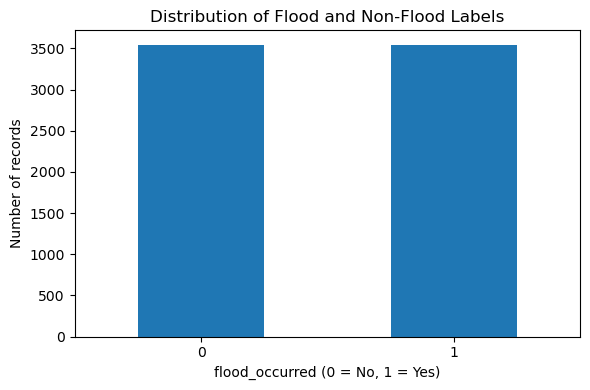

Class percentages:


,percent
flood_occurred,
0,50.0
1,50.0


In [10]:
target_counts = df["flood_occurred"].value_counts().sort_index()
display(target_counts.rename(index={0: "No flood (0)", 1: "Flood (1)"}).to_frame("records"))
ax = target_counts.plot(kind="bar", rot=0, figsize=(6, 4))
ax.set_title("Distribution of Flood and Non-Flood Labels")
ax.set_xlabel("flood_occurred (0 = No, 1 = Yes)")
ax.set_ylabel("Number of records")
plt.tight_layout()
plt.show()
print("Class percentages:")
display((target_counts / len(df) * 100).round(2).rename("percent").to_frame())

### 5.2 Univariate analysis — numerical variables

The histograms show the distribution and skewness of individual numeric features. Boxplots help identify spread and potential extreme values.

,count,mean,median,std,min,max
elevation_m,7086.0,962.45,990.60,171.70,353.01,1486.19
slope_deg,7086.0,4.99,4.15,3.57,0.04,26.37
river_distance_km,7086.0,2.41,1.53,2.81,0.05,40.80
drainage_density_km_per_km2,7086.0,1.38,1.15,0.98,0.05,8.00
built_up_pct,7086.0,28.96,28.41,18.66,0.00,100.00
population_density_per_km2,7086.0,410.08,238.13,557.72,20.00,13743.85
annual_rainfall_mm_2014,7086.0,1226.87,1028.11,945.62,0.00,10525.44
max_rainfall_24h_mm_2014,7086.0,95.25,88.77,57.53,0.00,711.06
max_rainfall_3d_mm_2014,7086.0,160.79,146.46,99.92,0.00,1188.72
max_rainfall_7d_mm_2014,7086.0,226.15,196.71,149.09,0.00,1611.20


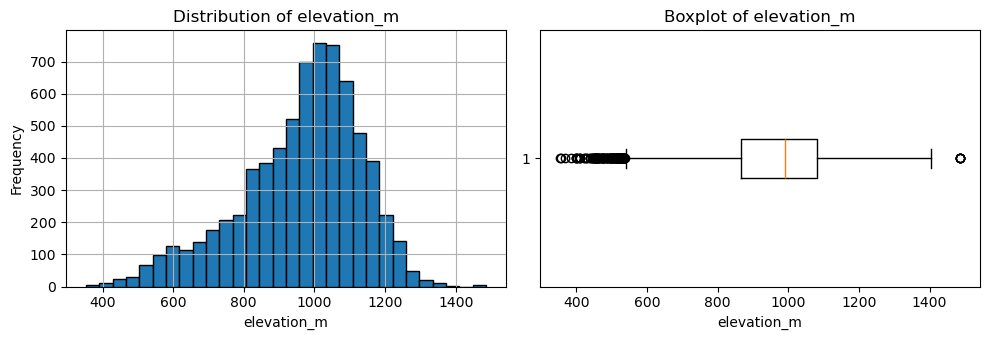

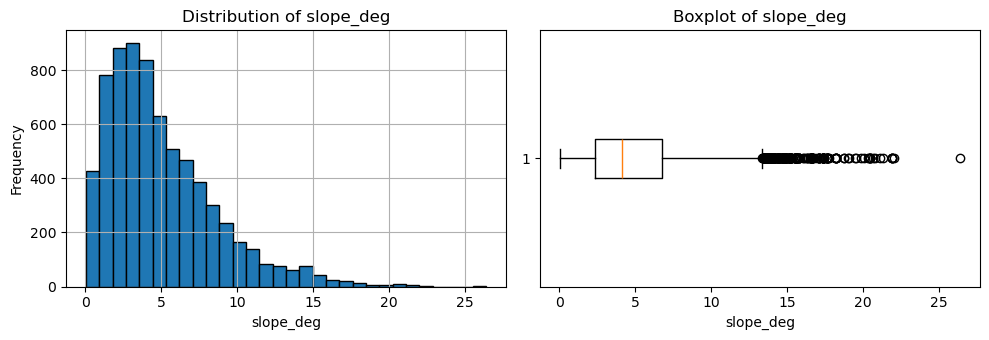

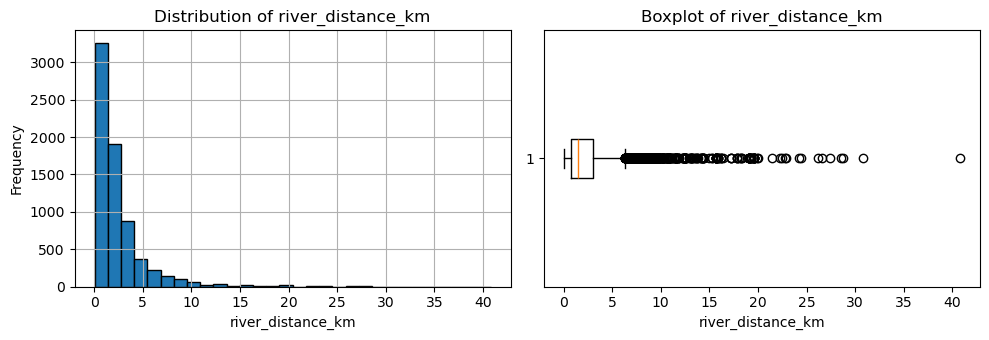

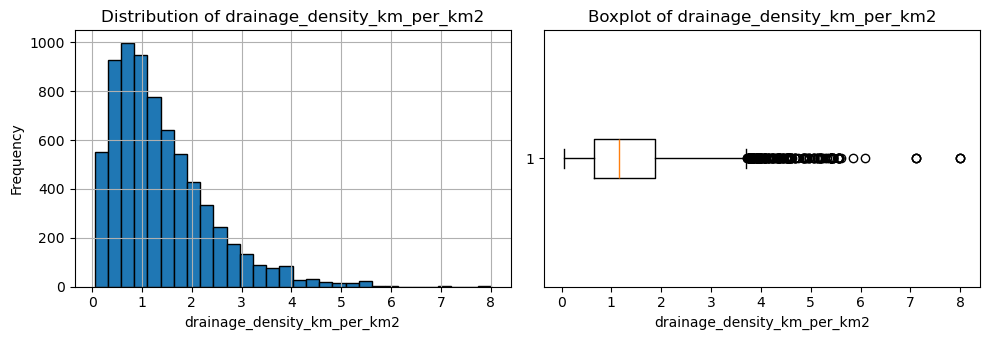

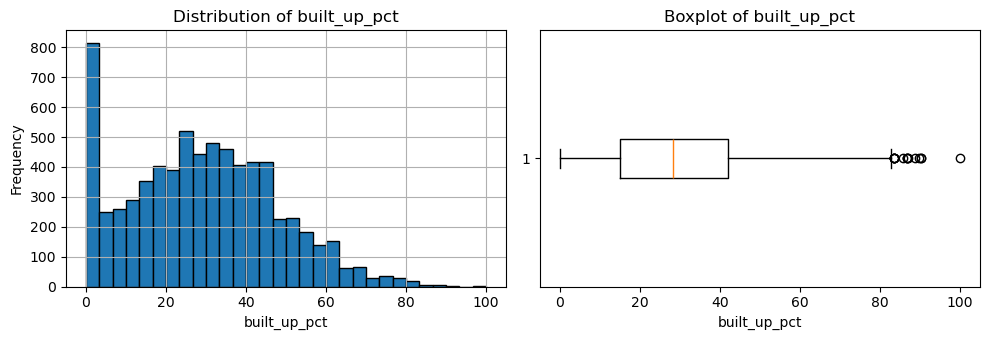

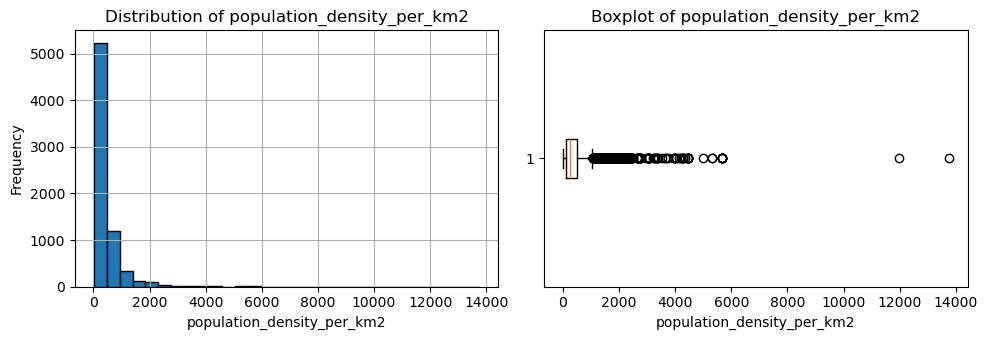

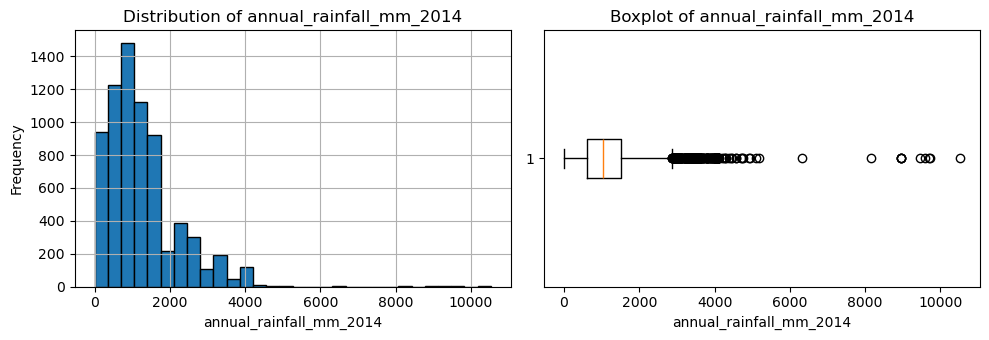

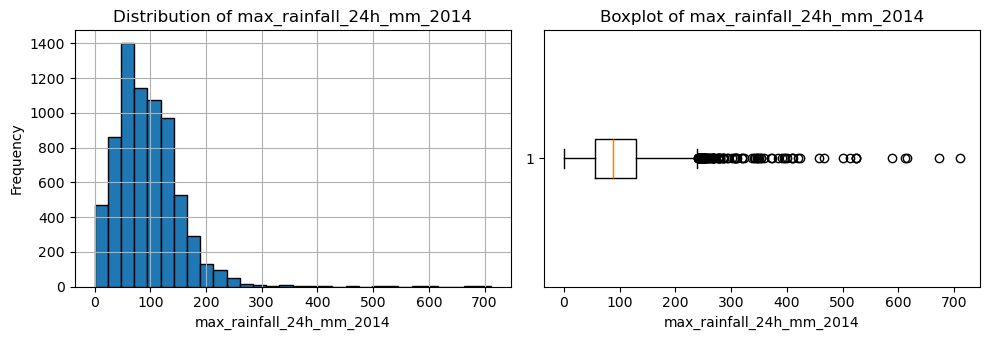

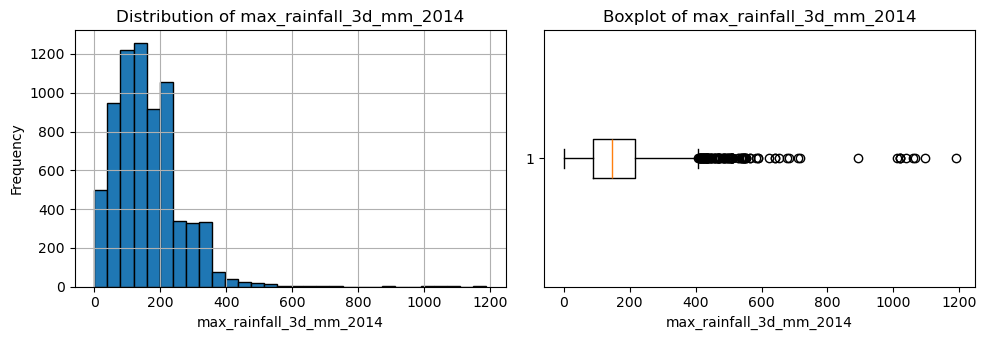

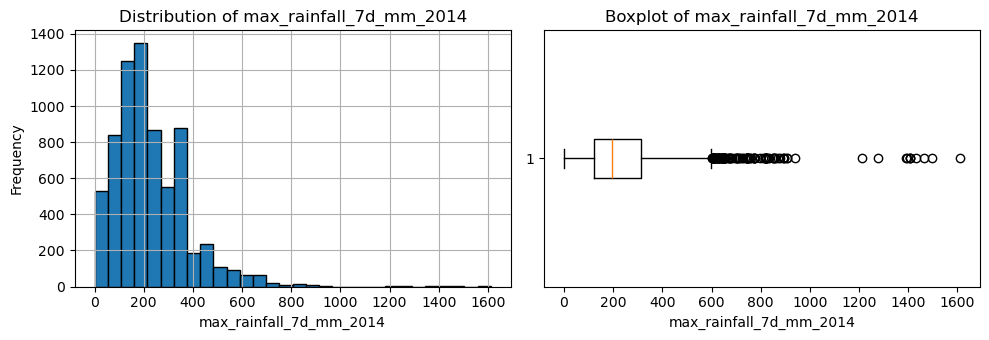

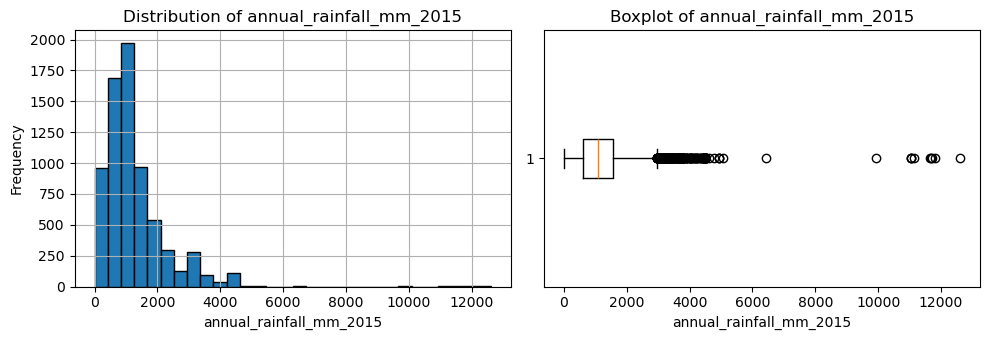

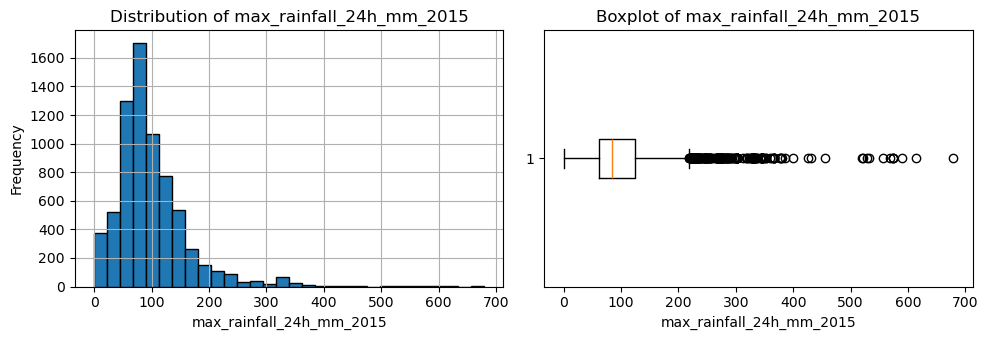

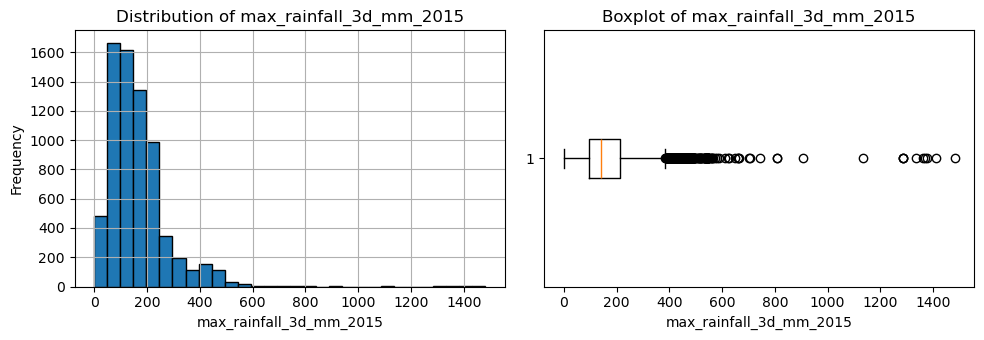

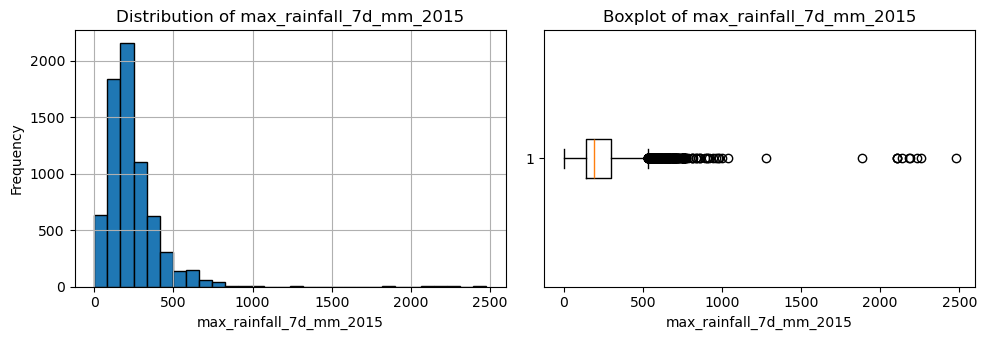

In [11]:
numeric_for_eda = [
    "elevation_m", "slope_deg", "river_distance_km", "drainage_density_km_per_km2",
    "built_up_pct", "population_density_per_km2", "annual_rainfall_mm_2014",
    "max_rainfall_24h_mm_2014", "max_rainfall_3d_mm_2014", "max_rainfall_7d_mm_2014",
    "annual_rainfall_mm_2015", "max_rainfall_24h_mm_2015",
    "max_rainfall_3d_mm_2015", "max_rainfall_7d_mm_2015"
]
numeric_for_eda = [c for c in numeric_for_eda if c in df.columns]

display(df[numeric_for_eda].agg(["count", "mean", "median", "std", "min", "max"]).T.round(2))

for col in numeric_for_eda:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    df[col].dropna().hist(bins=30, ax=axes[0], edgecolor="black")
    axes[0].set_title(f"Distribution of {col}")
    axes[0].set_xlabel(col)
    axes[0].set_ylabel("Frequency")
    axes[1].boxplot(df[col].dropna(), vert=False)
    axes[1].set_title(f"Boxplot of {col}")
    axes[1].set_xlabel(col)
    plt.tight_layout()
    plt.show()

### 5.3 Univariate analysis — categorical variables

Bar charts show the frequency of each category. The charts are useful for identifying dominant categories and rare categories.

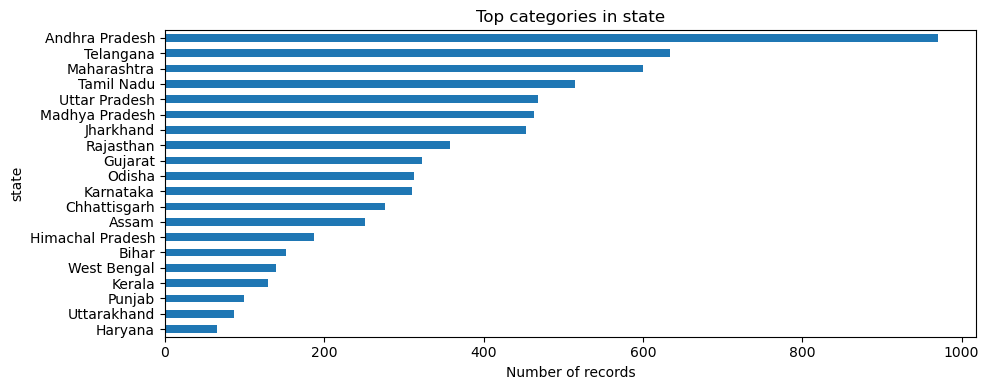

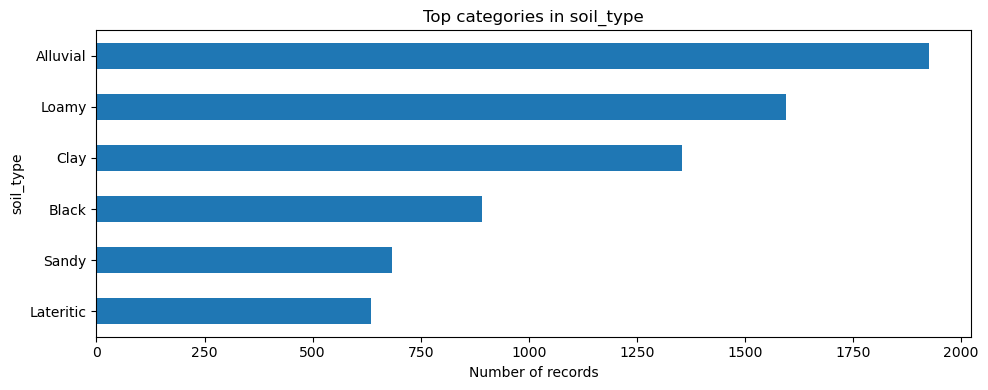

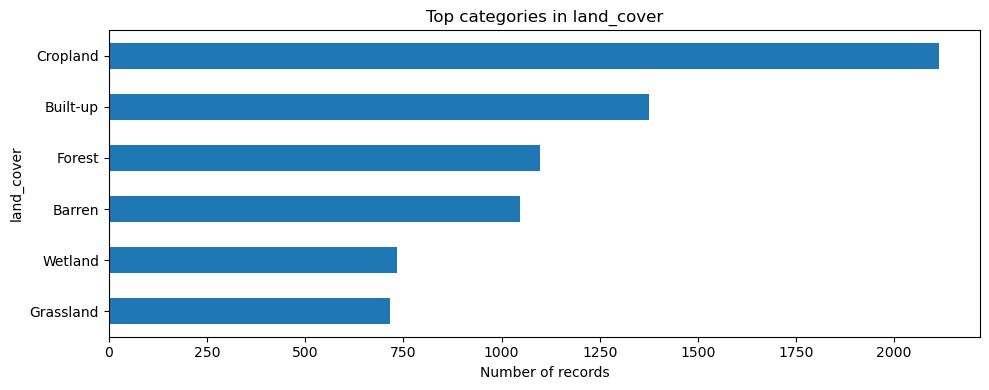

In [12]:
for col in ["state", "soil_type", "land_cover"]:
    counts = df[col].value_counts().head(20)
    plt.figure(figsize=(10, 4))
    counts.sort_values().plot(kind="barh")
    plt.title(f"Top categories in {col}")
    plt.xlabel("Number of records")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

### 5.4 Bivariate analysis — feature relationship with flood label

Boxplots compare numerical distributions across the two target classes. Grouped bar charts compare flood proportions across categories. These are descriptive associations, not proof of causation.

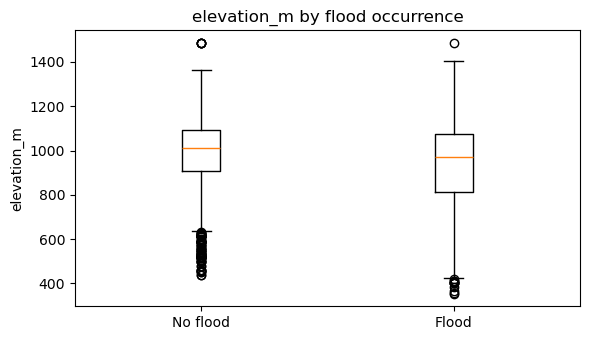

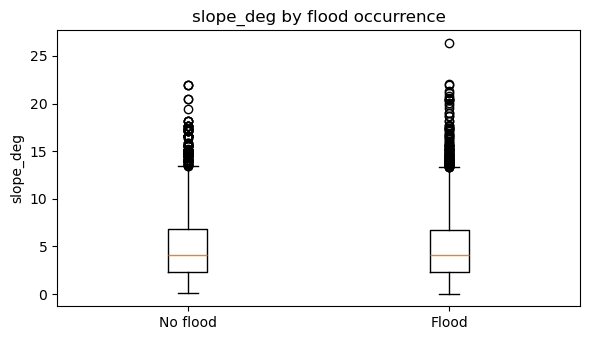

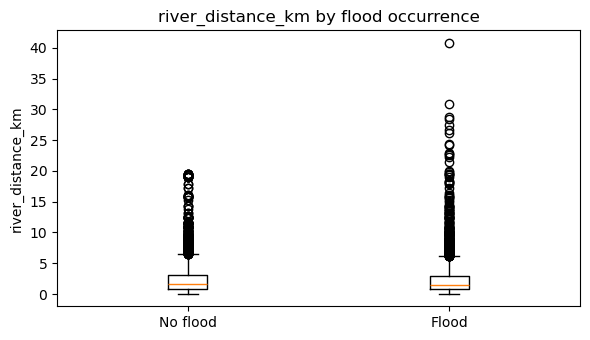

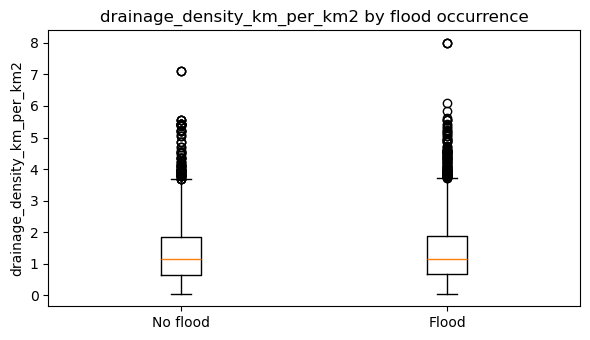

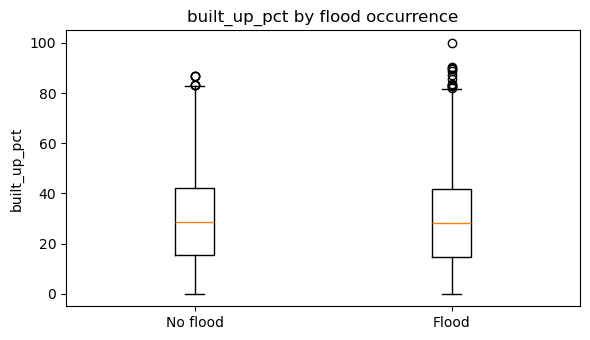

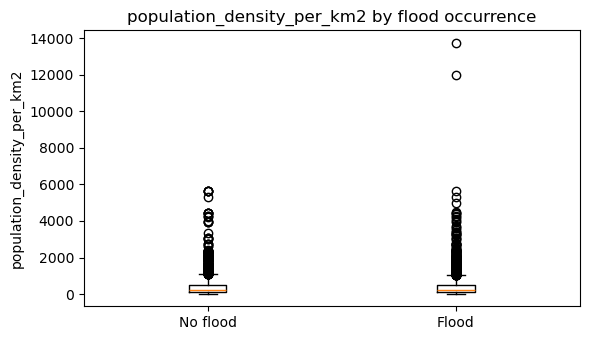

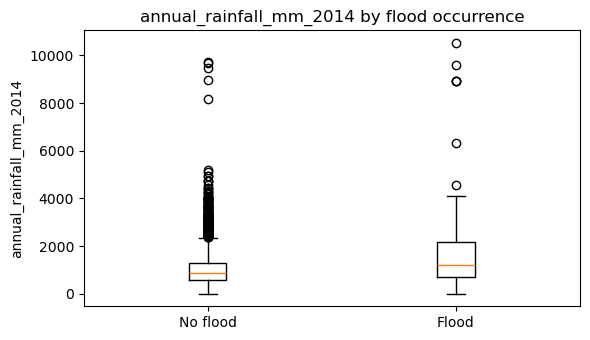

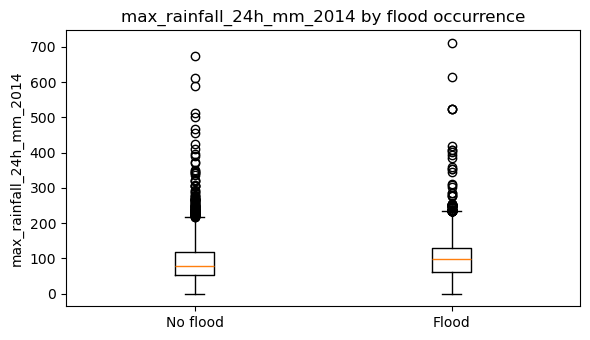

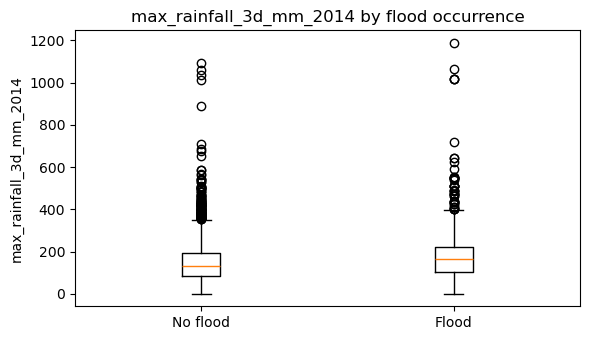

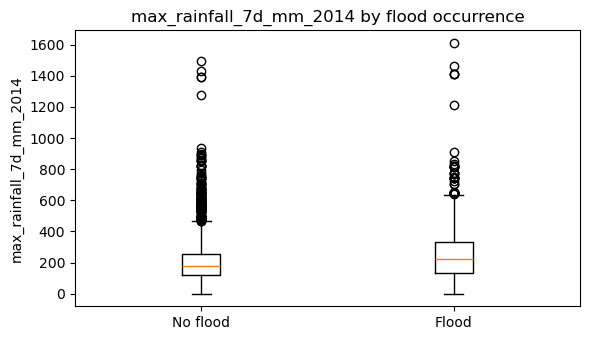

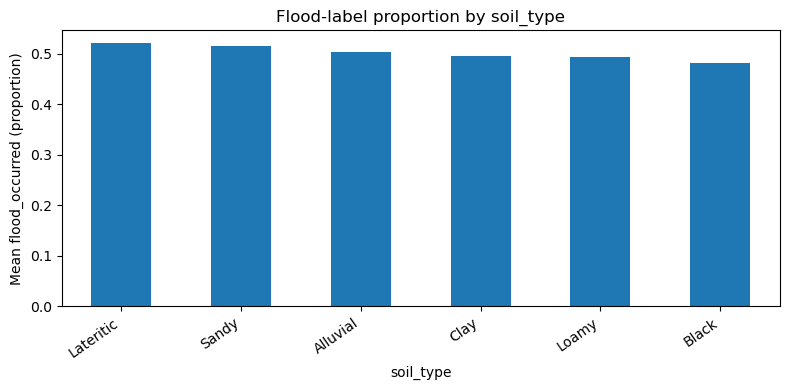

,records,flood_label_rate
soil_type,,
Lateritic,636,0.52044
Sandy,683,0.515373
Alluvial,1926,0.503634
Clay,1354,0.496307
Loamy,1596,0.494361
Black,891,0.481481


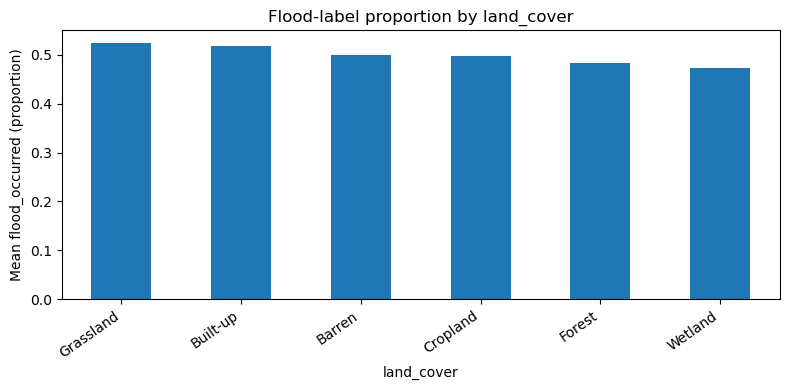

,records,flood_label_rate
land_cover,,
Grassland,716,0.523743
Built-up,1376,0.518169
Barren,1047,0.500478
Cropland,2113,0.49787
Forest,1099,0.484076
Wetland,735,0.472109


In [13]:
selected_bivariate = [
    "elevation_m", "slope_deg", "river_distance_km", "drainage_density_km_per_km2",
    "built_up_pct", "population_density_per_km2", "annual_rainfall_mm_2014",
    "max_rainfall_24h_mm_2014", "max_rainfall_3d_mm_2014", "max_rainfall_7d_mm_2014"
]
for col in selected_bivariate:
    if col in df:
        groups = [df.loc[df.flood_occurred == y, col].dropna() for y in [0, 1]]
        plt.figure(figsize=(6, 3.5))
        plt.boxplot(groups, labels=["No flood", "Flood"])
        plt.title(f"{col} by flood occurrence")
        plt.ylabel(col)
        plt.tight_layout()
        plt.show()

for col in ["soil_type", "land_cover"]:
    if col in df:
        rates = df.groupby(col)["flood_occurred"].mean().sort_values(ascending=False)
        plt.figure(figsize=(8, 4))
        rates.plot(kind="bar")
        plt.title(f"Flood-label proportion by {col}")
        plt.ylabel("Mean flood_occurred (proportion)")
        plt.xlabel(col)
        plt.xticks(rotation=35, ha="right")
        plt.tight_layout()
        plt.show()
        display(pd.DataFrame({
            "records": df[col].value_counts(),
            "flood_label_rate": df.groupby(col)["flood_occurred"].mean()
        }).sort_values("flood_label_rate", ascending=False))

### 5.5 Multivariate analysis — correlation heatmap

Pearson correlation is calculated for numeric columns. Correlation measures linear association and does not establish causation. Identifier, target-construction and sample metadata fields are excluded from the feature correlation view.

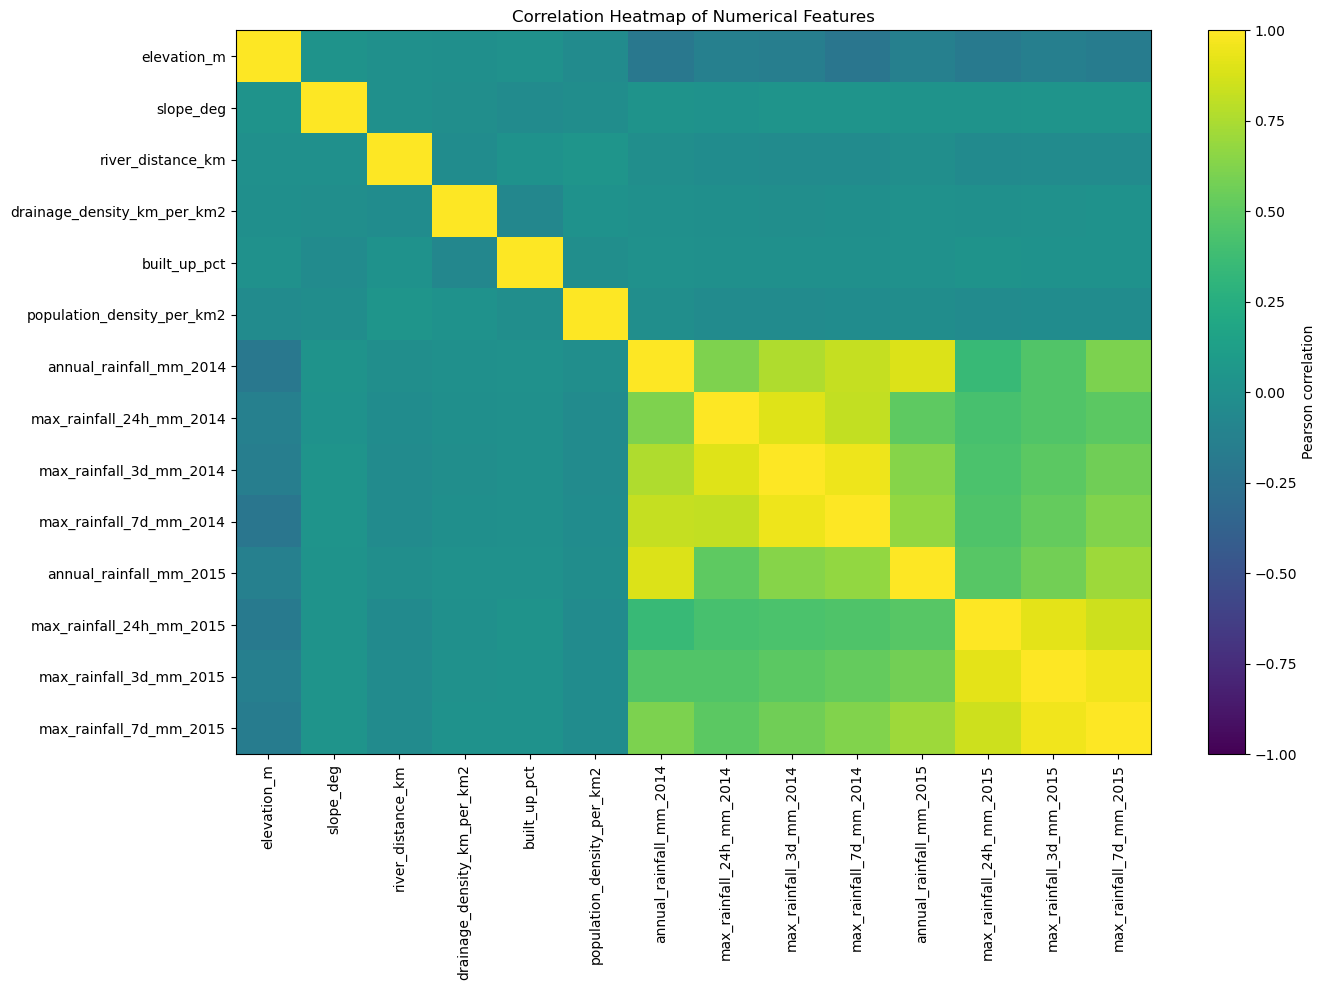

,,correlation
max_rainfall_3d_mm_2015,max_rainfall_7d_mm_2015,0.954624
max_rainfall_3d_mm_2014,max_rainfall_7d_mm_2014,0.949309
max_rainfall_24h_mm_2015,max_rainfall_3d_mm_2015,0.918430
max_rainfall_24h_mm_2014,max_rainfall_3d_mm_2014,0.898583
annual_rainfall_mm_2014,annual_rainfall_mm_2015,0.897351
max_rainfall_24h_mm_2015,max_rainfall_7d_mm_2015,0.846090
annual_rainfall_mm_2014,max_rainfall_7d_mm_2014,0.822445
max_rainfall_24h_mm_2014,max_rainfall_7d_mm_2014,0.813497
annual_rainfall_mm_2014,max_rainfall_3d_mm_2014,0.758337
annual_rainfall_mm_2015,max_rainfall_7d_mm_2015,0.705106


In [14]:
corr_cols = [c for c in numeric_for_eda if c not in ["sample_id"]]
corr = df[corr_cols].corr(numeric_only=True)
plt.figure(figsize=(14, 10))
im = plt.imshow(corr, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(im, label="Pearson correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

# Show strongest absolute correlations, excluding self-correlations
corr_pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
display(corr_pairs.reindex(corr_pairs.abs().sort_values(ascending=False).index).head(15).rename("correlation").to_frame())

### 5.6 Statistical summary and insights

In [15]:
print("Overall descriptive statistics")
display(df.describe(include="all").T)

print("Flood-label rate by state (top 15 by record count)")
state_summary = df.groupby("state").agg(
    records=("flood_occurred", "size"),
    flood_label_rate=("flood_occurred", "mean")
).sort_values("records", ascending=False)
display(state_summary.head(15))

print("Median numerical values by flood label")
display(df.groupby("flood_occurred")[numeric_for_eda].median().T.round(2))

Overall descriptive statistics


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
sample_id,7086.0,<NA>,<NA>,<NA>,3543.5,2045.696336,1.0,1772.25,3543.5,5314.75,7086.0
state,7086,30,Andhra Pradesh,970,NaN,NaN,NaN,NaN,NaN,NaN,NaN
district,7086,540,KRISHNA,147,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sub_district,7086,3546,PATAN,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
latitude,7086.0,NaN,NaN,NaN,23.03065,7.249842,8.004988,17.57248,23.5,28.010935,37.25
longitude,7086.0,NaN,NaN,NaN,80.846648,7.341287,68.0,75.25,79.25,86.024152,97.25
flood_occurred,7086.0,<NA>,<NA>,<NA>,0.5,0.500035,0.0,0.0,0.5,1.0,1.0
geographical_area_ha,7086.0,NaN,NaN,NaN,64251.054643,63428.91153,3.0,25758.2025,48398.075,85635.8,2140068.68
elevation_m,7086.0,NaN,NaN,NaN,962.452931,171.698985,353.013551,865.126832,990.597349,1082.061401,1486.190911
slope_deg,7086.0,NaN,NaN,NaN,4.988097,3.5715,0.040674,2.364253,4.14691,6.765422,26.366983


Flood-label rate by state (top 15 by record count)


,records,flood_label_rate
state,,
Andhra Pradesh,970,0.462887
Telangana,634,0.457413
Maharashtra,600,0.511667
Tamil Nadu,515,0.499029
Uttar Pradesh,469,0.550107
Madhya Pradesh,464,0.493534
Jharkhand,453,0.512141
Rajasthan,358,0.458101
Gujarat,323,0.569659


Median numerical values by flood label


flood_occurred,0,1
elevation_m,1009.81,969.23
slope_deg,4.15,4.14
river_distance_km,1.57,1.48
drainage_density_km_per_km2,1.15,1.15
built_up_pct,28.75,28.21
population_density_per_km2,236.64,239.41
annual_rainfall_mm_2014,858.94,1221.57
max_rainfall_24h_mm_2014,78.71,98.91
max_rainfall_3d_mm_2014,130.16,164.84
max_rainfall_7d_mm_2014,178.83,223.03


## 6. Key observations and interpretation

Use the outputs above to write the final interpretation. The following points are important when interpreting this particular file:

1. The target is exactly balanced in the supplied CSV (3,543 records in each class). This balance may be a result of sampling and should not be interpreted as the real-world prevalence of floods.
2. The negative class is explicitly named `pseudo_negative_matched_pool`. These are not necessarily verified flood-free observations. Describe them as pseudo-negative/control samples unless the creator confirms otherwise.
3. `sample_type` maps one-to-one to `flood_occurred` in the supplied file. It is target leakage and must be excluded from any model input.
4. Missing `rain_grid_latitude` and `rain_grid_longitude` values occur in the pseudo-negative class. This is a dataset-construction artefact and a possible leakage channel.
5. Observational differences in boxplots or category flood-label rates show associations in this sample. They do not prove that a variable causes flooding.
6. The data dictionary, exact spatial/temporal resolution, flood-label definition, pseudo-negative sampling method, and source lineage need confirmation from the dataset creator.